# 2.5 — Procesamiento: casos de IRA (semanal → mensual)

## Entradas

| Ruta | Contenido |
|------|-----------|
| `data/raw/salud/enf_resp_sonora_2010_2020.csv` | Casos por semana epidemiológica × municipio × sexo × grupo de edad × CLUES |

## Salidas

- `data/interim/salud/ira_hermosillo_semanal.csv` (opcional): `fecha_semana`, `anio`, `semana`, `casos_ira`.
- `data/interim/salud/ira_hermosillo_mensual.csv` (opcional): `fecha_mes`, `casos_ira`, `n_semanas`, `casos_ira_por_semana`, `anio_atipico`.

## Checklist

## 1. Filtrado Espacial y Delimitación del Alcance
- [ ] Aislar el dataset filtrando estrictamente por `clave_municipio == 30` (o `municipio == "HERMOSILLO"`).
- [ ] Validar que no existan registros con claves erróneas o de otros municipios.
- [ ] Comprobar el volumen de registros antes y después del filtro.

## 2. Agregación Temporal (Granularidad Semanal)
- [ ] Agrupar los datos crudos utilizando como llaves primarias `anio` y `semana`.
- [ ] Sumar los casos confirmados: `casos_ira_total = casos.sum()`.
- [ ] *(Opcional)* Mantener estratificación por `grupo_edad` o `genero` si se requiere.

## 3. Agregación Temporal (Granularidad Mensual)
- [ ] Agrupar los datos semanalmente por `anio` y `mes`.
- [ ] Sumar los casos confirmados: `casos_ira_total = casos.sum()`.
- [ ] *(Opcional)* Mantener estratificación por `grupo_edad` o `genero` si se requiere.

## 4. Auditoría y Control del Panel Temporal (Semanas Faltantes)
- [ ] Generar un panel temporal completo desde la Semana 1 de 2010 hasta la última de 2020.
- [ ] Detectar semanas epidemiológicas ausentes.
- [ ] Rellenar semanas sin registro con `0` casos.

## 5. Validación y Calidad de Datos
- [ ] Verificar que no existan valores nulos en las columnas clave (`anio`, `semana`, `casos_ira_total`).
- [ ] Detectar y documentar valores atípicos o inconsistencias (p. ej. semanas con 0 casos).
- [ ] Validar que el rango de fechas cubra el periodo de análisis (2010–2020).
- [ ] Asegurar tipado entero para `anio` y `semana`.
- [ ] *(Opcional)* Generar un reporte de calidad del dataset con métricas descriptivas.
- [ ] Generar y revisar el gráfico de la serie temporal (Sanity Check): Comprobar visualmente que los picos de invierno ocurren en los meses esperados y que el relleno de semanas faltantes con ceros no generó saltos extraños o caídas artificiales en la línea.


## 6. Persistencia de Resultados
- [ ] Guardar el dataset procesado en `data/interim/salud/ira_hermosillo_semanal.csv` y `data/interim/salud/ira_hermosillo_mensual.csv`.
- [ ] Incluir metadatos en el archivo (fecha de procesamiento, versión del script, criterios de filtrado).
- [ ] *(Opcional)* Generar un resumen estadístico del dataset procesado para auditoría.


## Configuración e imports

In [2]:
from pathlib import Path
import sys
import os 

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))


from sonora_health_climate_eda.config import (
    HERMOSILLO_CVE_MUN,
    PROCESSED_DATA_DIR,
    INTERIM_DATA_DIR,
    RAW_DATA_DIR,
)
from sonora_health_climate_eda.panel import health_ira_monthly, health_ira_weekly
from sonora_health_climate_eda.processing import validar_y_auditar_calidad, construir_panel_temporal, cargar_y_filtrar_salud
from sonora_health_climate_eda.plots import plot_serie_temporal_ira

SALUD_RAW = RAW_DATA_DIR / "salud" / "enf_resp_sonora_2010_2020.csv"
HERMOSILLO_CLAVE_SALUD = int(HERMOSILLO_CVE_MUN) % 1000  # 26030 -> 30 (clave en la fuente)
OUT_DIR = INTERIM_DATA_DIR / "salud"
FINAL_DIR = PROCESSED_DATA_DIR / "salud"
FINAL_OUT = FINAL_DIR / "salud_ira_hermosillo.csv"

## 1. Filtrado Espacial y Delimitación del Alcance

In [3]:
df_raw = cargar_y_filtrar_salud(SALUD_RAW)

 [INGESTA] Registros totales en crudo: 961576
 [FILTRO] Registros filtrados para Hermosillo: 200722


## 2. Agregación Temporal (Granularidad Semanal)

In [4]:
df_semanal = health_ira_weekly()
df_semanal.head()

2026-11-13 22:55:31.743 -07:00 | INFO     | sonora_health_climate_eda.panel:health_ira_weekly:510 - Salud IRA Hermosillo: 313 semanas, 1129099 casos en ventana.


,fecha_semana,anio,semana,casos_ira_total
0,2015-01-04,2015,1,5463
1,2015-01-11,2015,2,5898
2,2015-01-18,2015,3,6160
3,2015-01-25,2015,4,6515
4,2015-02-01,2015,5,5914


In [5]:
df_mensual = health_ira_monthly()
df_mensual.head()

2026-11-13 22:55:35.078 -07:00 | INFO     | sonora_health_climate_eda.panel:health_ira_weekly:510 - Salud IRA Hermosillo: 313 semanas, 1129099 casos en ventana.


,fecha_mes,casos_ira,n_semanas,casos_ira_total
0,2015-01-01,24036,4,6009.0
1,2015-02-01,21622,4,5405.5
2,2015-03-01,20961,5,4192.2
3,2015-04-01,11138,4,2784.5
4,2015-05-01,14120,5,2824.0


## 4. Auditoría y Control del Panel Temporal (Semanas Faltantes)

In [6]:
df_panel = construir_panel_temporal(df_semanal)
df_panel.head()

[PANEL] Semanas faltantes reales detectadas e imputadas con 0: 1


,anio,semana,fecha_semana,casos_ira_total,clave_municipio,municipio
0,2015,1,2015-01-04,5463,30,HERMOSILLO
1,2015,2,2015-01-11,5898,30,HERMOSILLO
2,2015,3,2015-01-18,6160,30,HERMOSILLO
3,2015,4,2015-01-25,6515,30,HERMOSILLO
4,2015,5,2015-02-01,5914,30,HERMOSILLO


## 4. Validación, Calidad de Datos y Sanity Check Visual

In [7]:
# Ejecutar la validación y generar el reporte de calidad
reporte_calidad = validar_y_auditar_calidad(df_panel)

Ejecutando auditoría de calidad de datos...
 [OK] Cero valores nulos en columnas clave (`anio`, `semana`, `casos_ira_total`).
 [OK] El rango temporal cubre el periodo esperado: 2015 - 2020.
 Se detectaron 1 semanas con 0 casos de IRA (imputadas o sin reporte).
 Se detectaron 0 semanas con picos atípicos altos de casos (por encima de IQR).

--- RESUMEN DEL REPORTE DE CALIDAD ---
   • total_registros_semanales: 314
   • casos_totales_periodo: 1129099
   • media_semanal: 3595.86
   • mediana_semanal: 3593.5
   • desviacion_estandar: 1722.04
   • min_casos_semanales: 0
   • max_casos_semanales: 8148
------------------------------------------



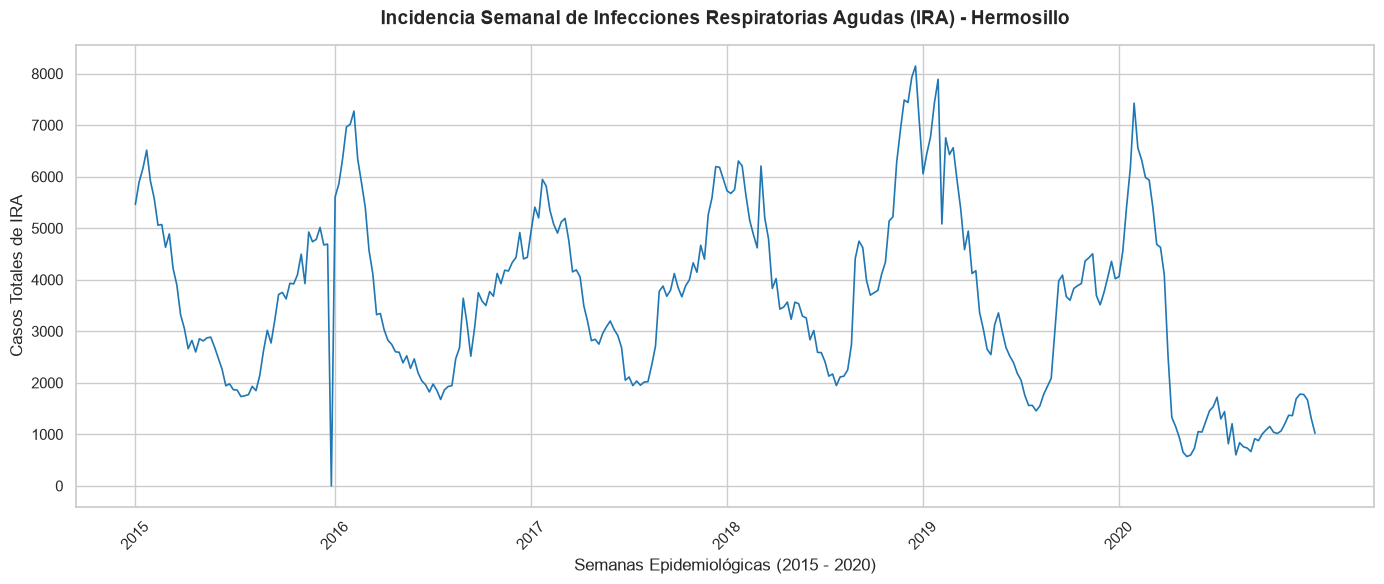

In [8]:
plot_serie_temporal_ira(df_panel)

Nota: El año 2015 tiene formalmente 53 semanas según la norma internacional (la fecha del 28 de diciembre de 2015 cae en una semana que pertenece al ciclo de 53 semanas de ese año en particular).

## Guardar salida

In [9]:
# Ordenar columnas para el merge final
df_final = df_panel[['clave_municipio', 'municipio', 'anio', 'semana', 'casos_ira_total']]

# Exportar (asegurarse de que el directorio data/processed exista)
os.makedirs(FINAL_DIR, exist_ok=True)
df_final.to_csv(FINAL_OUT, index=False)

print('¡Procesamiento completado con éxito!')
display(df_final.head(5))

¡Procesamiento completado con éxito!


,clave_municipio,municipio,anio,semana,casos_ira_total
0,30,HERMOSILLO,2015,1,5463
1,30,HERMOSILLO,2015,2,5898
2,30,HERMOSILLO,2015,3,6160
3,30,HERMOSILLO,2015,4,6515
4,30,HERMOSILLO,2015,5,5914
